In [1]:
import numpy as np
import matplotlib.pyplot as plt
from lmfit import models
from scipy.optimize import leastsq
from scipy.optimize import curve_fit

In [127]:
#funties om te gebruiken
def importeer(datanaam):
    x_as = []
    y_as = []

    # open file in read mode
    with open(datanaam, 'r', newline='') as file:

        # read and discard first line of file
        next(file)

        for line in file:
            # split column

            line_splitted = line.split(',')
            x = (float(line_splitted[3]))
            y = float(line_splitted[4])
            if x < 0.015:
                x_as.append(x)
                y_as.append(y)

    return x_as, y_as

def lineaire_functie(x,a,b):
    return a*x + b
def plot(x_as, y_as, x_label, y_label):
    plt.plot(x_as, y_as, )
    plt.xlabel(x_label)
    plt.ylabel(y_label)
    plt.title('')
    plt.show()

def lorentz(x, x0, gamma, A):
    return A * (0.5*gamma)**2 / ((x - x0)**2 + (0.5*gamma)**2)

def multi_lorentz(x, *params):
    # Laatste parameter is de achtergrond
    B = params[-1]
    y_model = np.zeros_like(x) + B

    # Door de overige parameters in stapjes van 3 lopen
    # (x0, gamma, A) per piek
    for i in range(0, len(params) - 1, 3):
        x0 = params[i]
        gamma = params[i + 1]
        A = params[i + 2]
        y_model += lorentz(x, x0, gamma, A)

    return y_model

def sin_functie(x, A, f, phi, B):
    y= A * np.sin(2 * np.pi * f * x + phi) + B
    return y

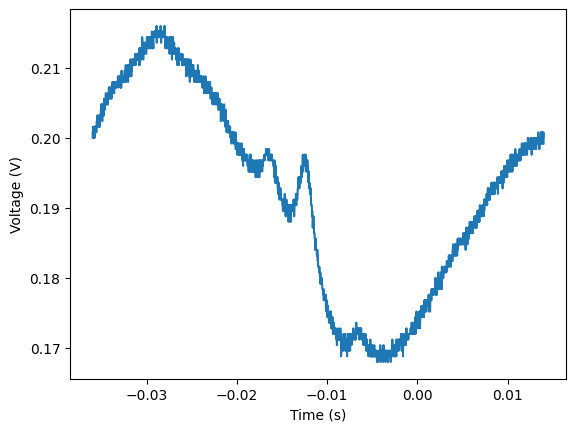

In [128]:
#Importeren van de Data: 
x,y = importeer('/Users/timwiemer/Desktop/Natuur-: Sterrenkunde/Jaar 1/Project/Rubium_Spectroscopy/programmas.venv/TEK0007.CSV')
plot(x, y, 'Time (s)', 'Voltage (V)')

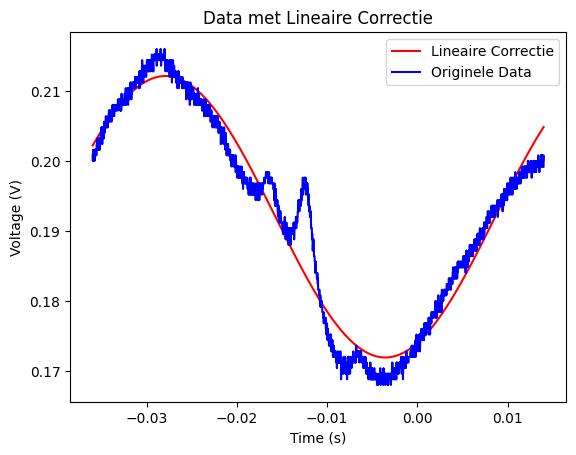

In [129]:
# de grafiek ligt nog schuin, dus moeten we dit corrigeren, 
#De lijn gaat linear omlaag, dit weten we omdat de oscilloscoop een lineaire lijn volgt

# y_max = max(y)
# x_max = x[y.index(y_max)]
# y_min = min(y)
# x_min = x[y.index(y_min)]

# helling = (y_max - y_min) / (x_max - x_min)

# startpunt = y_max - helling * x_max




#Voor een andere is een sinus functie beter, deze heeft een amplitude, frequentie, fase en achtergrond

mod_sin = models.Model(sin_functie)

fit_result = mod_sin.fit(y, x=x, A=0.1, f=1, phi=0, B=0.5)        

A =fit_result.params['A'].value
DA = fit_result.params['A'].stderr
f = fit_result.params['f'].value
Df = fit_result.params['f'].stderr
phi = fit_result.params['phi'].value
Dphi = fit_result.params['phi'].stderr
B = fit_result.params['B'].value
DB = fit_result.params['B'].stderr

# nu kunnen we de lineaire functie gebruiken om de lijn te corrigeren
y_corr = []
for i in range(len(x)):
    #y_corr.append(helling * x[i] + startpunt)
    y_corr.append(sin_functie(x[i], A, f, phi, B))

plt.plot(x, y_corr, label='Lineaire Correctie', color='red')
plt.plot(x, y, label='Originele Data', color='blue')
plt.xlabel('Time (s)')
plt.ylabel('Voltage (V)')
plt.title('Data met Lineaire Correctie')
plt.legend()
plt.show()



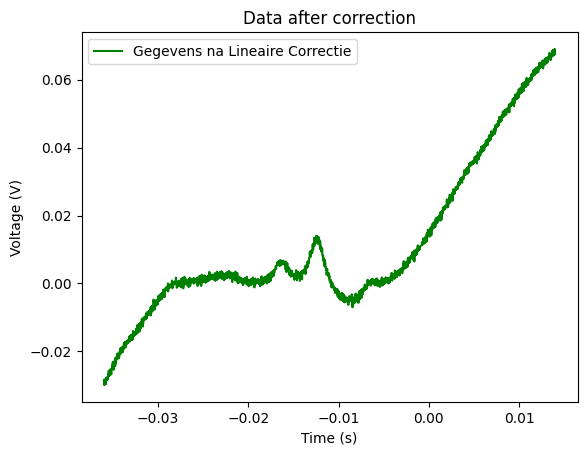

In [124]:
#then we subtract the linear line from the actual data

y_subtracted = []
for i in range(len(x)):
    y_subtracted.append(y[i] - y_corr[i])   

plt.plot(x, y_subtracted, label='Gegevens na Lineaire Correctie', color='green')
plt.xlabel('Time (s)')
plt.ylabel('Voltage (V)')
plt.title('Data after correction')
plt.legend()
plt.show()

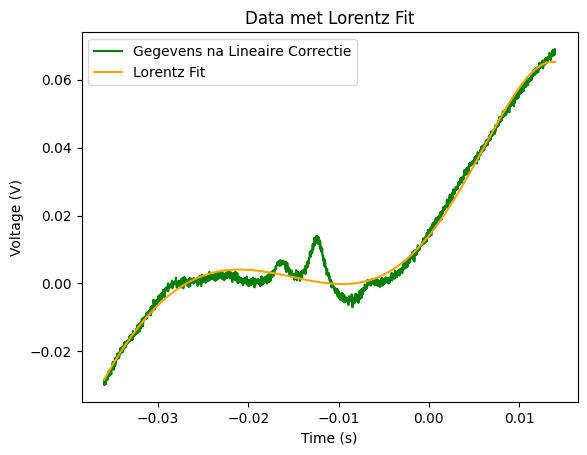

Piek 1: x0 = -0.03092 ± 0.00193
         gamma = -0.12530 ± 0.03346
         A     = 0.97959 ± 0.62887
Piek 2: x0 = 0.01900 ± 0.00151
         gamma = -0.04490 ± 0.00285
         A     = 0.51848 ± 0.16663
Achtergrond B = -1.07569 ± 0.66122


In [131]:
#now we need to find a lorenzian function somehow...
x = np.array(x)
y_subtracted = np.array(y_subtracted)

x0_list = [-0.016, 0.012 ]  
gamma_guess = 0.001  
B_guess = 0.001     

p0 = []  # startwaarden
A_list = [-0.007, -0.005, ]  # schat per piek visueel

for x0, A_guess in zip(x0_list, A_list):
    p0.extend([x0, gamma_guess, A_guess])

p0.append(B_guess)


popt, pcov = curve_fit(multi_lorentz, x, y_subtracted, p0=p0)
y_fit = multi_lorentz(x, *popt)

plt.plot(x, y_subtracted, label='Gegevens na Lineaire Correctie', color='green')
plt.plot(x, y_fit, label='Lorentz Fit', color='orange')
plt.xlabel('Time (s)')
plt.ylabel('Voltage (V)')
plt.title('Data met Lorentz Fit')
plt.legend()
plt.show()

N = len(x0_list)  # aantal pieken

import numpy as np

perr = np.sqrt(np.diag(pcov))  # standaardafwijking per parameter

for i in range(N):
    print(f"Piek {i+1}: x0 = {popt[i*3]:.5f} ± {perr[i*3]:.5f}")
    print(f"         gamma = {popt[i*3+1]:.5f} ± {perr[i*3+1]:.5f}")
    print(f"         A     = {popt[i*3+2]:.5f} ± {perr[i*3+2]:.5f}")

print(f"Achtergrond B = {popt[-1]:.5f} ± {perr[-1]:.5f}")